# Modelado: comparación, evaluación por segmentos y explicabilidad

Este notebook analiza los resultados de `src/modelado.py`, que ajusta los hiperparámetros de
cada modelo con Optuna (validación cruzada de 5 particiones sobre el conjunto de entrenamiento)
y los evalúa una única vez sobre el conjunto de prueba.

Para reproducir los resultados:

```bash
python src/preprocesado.py
python src/modelado.py --pruebas 40
```

Todas las métricas se expresan en la **escala original (euros)**: los modelos se entrenan sobre
log(precio) y sus predicciones se devuelven a euros con la exponencial antes de evaluarlas. El ajuste
de hiperparámetros minimiza el RMSE de log(precio) en validación cruzada, que es la función de pérdida
con la que se entrenan los modelos; ese valor solo se usa como criterio interno de ajuste y de
selección del modelo.

Contenido:

1. Comparación de modelos y búsqueda de hiperparámetros.
2. Calidad de las predicciones del mejor modelo.
3. Rendimiento por tipo de vivienda, localización y tramo de precio.
4. Variables del anuncio (ablación).
5. Explicabilidad con SHAP.
6. Conclusiones, limitaciones y trabajo futuro.

Las figuras se guardan en `doc/figuras/modelado/`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import shap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from preprocesado import preparar  # noqa: E402

RES = RAIZ / "data" / "procesado" / "resultados"
FIGURAS = RAIZ / "doc" / "figuras" / "modelado"
FIGURAS.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
miles = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
NOMBRES = {"lineal": "Regresión lineal", "random_forest": "Random Forest", "xgboost": "XGBoost",
           "lightgbm": "LightGBM", "catboost": "CatBoost"}

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    plt.show()

res = pd.read_csv(RES / "resultados_modelos.csv")
pred = pd.read_csv(RES / "predicciones_prueba.csv", dtype={"id_anuncio": str})
hiper = json.load(open(RES / "hiperparametros.json", encoding="utf-8"))
MEJOR = res.sort_values("CV_RMSE_log").iloc[0]["modelo"]
print("Mejor modelo según validación cruzada:", NOMBRES[MEJOR])

Mejor modelo según validación cruzada: LightGBM


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Comparación de modelos

In [2]:
COLUMNAS_TABLA = {
    "CV_MAE_eur": "MAE € (CV)", "CV_MAE_eur_desv": "± desv.", "CV_RMSE_eur": "RMSE € (CV)",
    "CV_MdAPE_pct": "MdAPE % (CV)", "CV_R2_eur": "R² (CV)",
    "test_MAE_eur": "MAE € (prueba)", "test_RMSE_eur": "RMSE € (prueba)", "test_MAPE_pct": "MAPE % (prueba)",
    "test_MdAPE_pct": "MdAPE % (prueba)", "test_R2_eur": "R² (prueba)"}
def tabla_metricas(df):
    t = df[list(COLUMNAS_TABLA)].rename(columns=COLUMNAS_TABLA)
    return t.round({c: (0 if "€" in c or c == "± desv." else 3 if "R²" in c else 1) for c in t.columns})

tabla = tabla_metricas(res.set_index("modelo").rename(index=NOMBRES))
tabla["minutos"] = res.set_index("modelo").rename(index=NOMBRES)["minutos"].round(1)
tabla

,MAE € (CV),± desv.,RMSE € (CV),MdAPE % (CV),R² (CV),MAE € (prueba),RMSE € (prueba),MAPE % (prueba),MdAPE % (prueba),R² (prueba),minutos
modelo,,,,,,,,,,,
LightGBM,78091.0,6078.0,163002.0,16.9,0.752,81199.0,180857.0,22.8,16.4,0.738,2.5
XGBoost,78642.0,7218.0,165877.0,16.6,0.743,79169.0,177459.0,22.2,16.3,0.748,3.9
CatBoost,78863.0,5902.0,163120.0,17.3,0.752,82957.0,182761.0,22.8,16.9,0.732,16.4
Random Forest,83405.0,6934.0,175480.0,18.0,0.714,85821.0,195224.0,24.3,17.6,0.695,3.4
Regresión lineal,101042.0,7697.0,196257.0,22.9,0.644,104681.0,220438.0,30.3,23.0,0.611,0.0


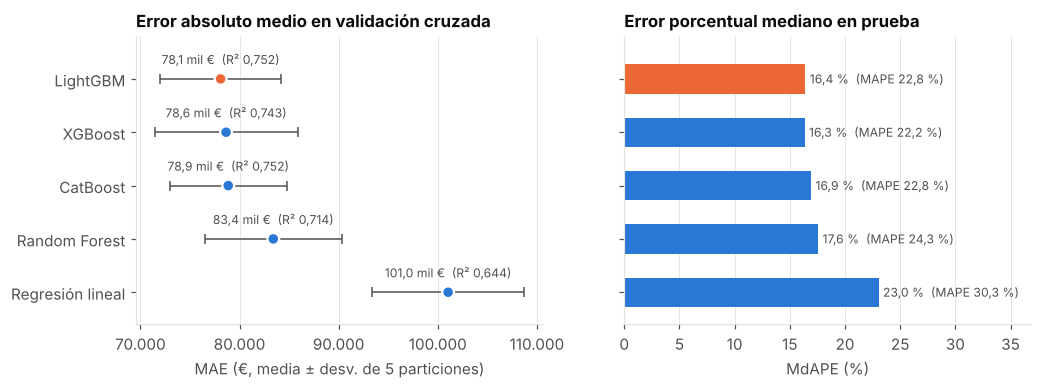

In [3]:
orden = res.sort_values("CV_RMSE_log", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
y = np.arange(len(orden))
colores = [NARANJA if m == MEJOR else AZUL for m in orden["modelo"]]
ax[0].errorbar(orden["CV_MAE_eur"], y, xerr=orden["CV_MAE_eur_desv"], fmt="none", ecolor=TINTA_2,
               capsize=3, linewidth=1)
ax[0].scatter(orden["CV_MAE_eur"], y, color=colores, s=60, zorder=3, edgecolor="white", linewidth=1.5)
for yi, (v, r2) in enumerate(zip(orden["CV_MAE_eur"], orden["CV_R2_eur"])):
    ax[0].text(v, yi + 0.28, f"{v/1000:,.1f} mil €  (R² {r2:.3f})".replace(",", "X").replace(".", ",").replace("X", "."),
               fontsize=8, color=TINTA_2, ha="center")
ax[0].xaxis.set_major_formatter(miles)
ax[0].set(title="Error absoluto medio en validación cruzada", xlabel="MAE (€, media ± desv. de 5 particiones)")
ax[0].set_ylim(-0.6, len(orden) - 0.2)
ax[0].set_yticks(y, [NOMBRES[m] for m in orden["modelo"]]); ax[0].grid(axis="y", visible=False)

ax[1].barh(y, orden["test_MdAPE_pct"], color=colores, height=0.55)
for yi, (md_, mp) in enumerate(zip(orden["test_MdAPE_pct"], orden["test_MAPE_pct"])):
    ax[1].text(md_ + 0.4, yi, f"{md_:.1f} %  (MAPE {mp:.1f} %)".replace(".", ","), va="center", fontsize=8, color=TINTA_2)
ax[1].set_xlim(0, orden["test_MdAPE_pct"].max() * 1.6)
ax[1].set(title="Error porcentual mediano en prueba", xlabel="MdAPE (%)")
ax[1].grid(axis="y", visible=False)
guardar(fig, "01_comparacion_modelos")

**Lectura.**

- Los tres modelos de *gradient boosting* superan claramente a Random Forest y a la regresión lineal, y están **prácticamente empatados entre sí**: sus diferencias en validación cruzada son mucho menores que la variabilidad entre particiones.
- **LightGBM** obtiene el menor error de ajuste (RMSE de log(precio) 0,300 ± 0,008) y el menor MAE en validación cruzada (78.091 € ± 6.078 €, R² 0,752), y se selecciona como modelo de referencia.
- En **prueba**, LightGBM alcanza un MAE de 81.199 €, un R² de 0,738, una MdAPE del 16,4 % y un MAPE del 22,8 %. XGBoost queda algo mejor en prueba (MAE 79.169 €, R² 0,748), pero la selección se hace por validación cruzada, fijada antes de mirar el conjunto de prueba. Con 1.362 viviendas, diferencias de este tamaño no son concluyentes.
- Frente a la regresión lineal (MAE 104.681 €, MdAPE 23,0 %), el error baja en torno a un 22 %, lo que confirma que la relación entre las variables y el precio es no lineal.

**Por qué el R² en euros es más bajo que en escala logarítmica.** En euros, el R² y el RMSE (180.857 €) están dominados por las pocas viviendas de más de un millón de euros, donde un error relativo moderado supone cientos de miles de euros. Por eso se acompañan siempre de métricas relativas (MdAPE y MAPE), que pesan igual a todas las viviendas.

La predicción en euros se obtiene como exp(predicción en log), que estima la **mediana** condicionada del precio. Se probó la corrección de Duan (*smearing*), que estima la media: sube el R² en euros, pero empeora el MAE y la MdAPE, así que no se aplica.

### Búsqueda de hiperparámetros

Para cada modelo, Optuna (muestreador TPE, semilla 42) prueba 40 combinaciones de hiperparámetros
dentro de los rangos de la tabla siguiente y elige la que minimiza el RMSE de log(precio) en
validación cruzada de 5 particiones. Los rangos de escala logarítmica se muestrean de forma uniforme
en logaritmo, lo que es adecuado para tasas de aprendizaje y términos de regularización, cuyo efecto
depende del orden de magnitud. La regresión lineal no tiene hiperparámetros.

In [4]:
esp = pd.read_csv(RES / "espacios_busqueda.csv")
def rango(f):
    if f["tipo"] in ("categórico", "fijo"):
        return f"{{{f['valores']}}}" if f["tipo"] == "categórico" else f"{f['valores']} (fijo)"
    fmt = (lambda v: f"{v:g}")
    paso = f", paso {f['paso']:g}" if f["tipo"] == "entero" and pd.notna(f["paso"]) and f["paso"] != 1 else ""
    return f"[{fmt(f['minimo'])}, {fmt(f['maximo'])}]{paso}" + (" (log)" if f["escala"] == "log" else "")
def elegido(f):
    v = hiper.get(f["modelo"], {}).get(f["parametro"])
    return "" if v is None else (f"{v:.4g}" if isinstance(v, float) else str(v))
esp["rango"] = esp.apply(rango, axis=1)
esp["valor elegido"] = esp.apply(elegido, axis=1)
esp["modelo"] = esp["modelo"].map(NOMBRES)
esp.to_csv(RES / "tabla_hiperparametros.csv", index=False, encoding="utf-8-sig")
esp.set_index(["modelo", "parametro"])[["tipo", "rango", "valor elegido"]]

tipo                  rango  \
modelo        parametro                                                
Random Forest n_estimators             entero   [200, 700], paso 100   
              max_features               real               [0.1, 1]   
              min_samples_leaf         entero                [1, 10]   
              max_depth            categórico     {None, 15, 25, 40}   
XGBoost       n_estimators             entero  [200, 1500], paso 100   
              learning_rate              real      [0.01, 0.2] (log)   
              max_depth                entero                [3, 10]   
              min_child_weight           real          [1, 20] (log)   
              subsample                  real               [0.6, 1]   
              colsample_bytree           real               [0.2, 1]   
              reg_lambda                 real      [0.001, 10] (log)   
              reg_alpha                  real      [0.001, 10] (log)   
LightGBM      n_estimators             entero  [200, 1500], paso 100   
              learning_rate              real      [0.01, 0.2] (log)   
              num_leaves               entero              [15, 127]   
              min_child_samples        entero                [5, 80]   
              subsample                  real               [0.6, 1]   
              colsample_bytree           real               [0.2, 1]   
              reg_lambda                 real      [0.001, 10] (log)   
              reg_alpha                  real      [0.001, 10] (log)   
              subsample_freq             fijo               1 (fijo)   
CatBoost      iterations               entero  [300, 2000], paso 100   
              learning_rate              real      [0.02, 0.2] (log)   
              depth                    entero                [4, 10]   
              l2_leaf_reg                real          [1, 20] (log)   
              bagging_temperature        real                 [0, 1]   

                                  valor elegido  
modelo        parametro                          
Random Forest n_estimators                  600  
              max_features               0.3456  
              min_samples_leaf                1  
              max_depth                          
XGBoost       n_estimators                 1400  
              learning_rate             0.01771  
              max_depth                       7  
              min_child_weight            3.364  
              subsample                  0.9086  
              colsample_bytree           0.2784  
              reg_lambda                0.00144  
              reg_alpha                0.001659  
LightGBM      n_estimators                  500  
              learning_rate             0.03467  
              num_leaves                     69  
              min_child_samples              14  
              subsample                  0.8362  
              colsample_bytree           0.2035  
              reg_lambda                0.04902  
              reg_alpha                 0.05113  
              subsample_freq                  1  
CatBoost      iterations                   1600  
              learning_rate             0.06629  
              depth                           6  
              l2_leaf_reg                 5.467  
              bagging_temperature       0.04639

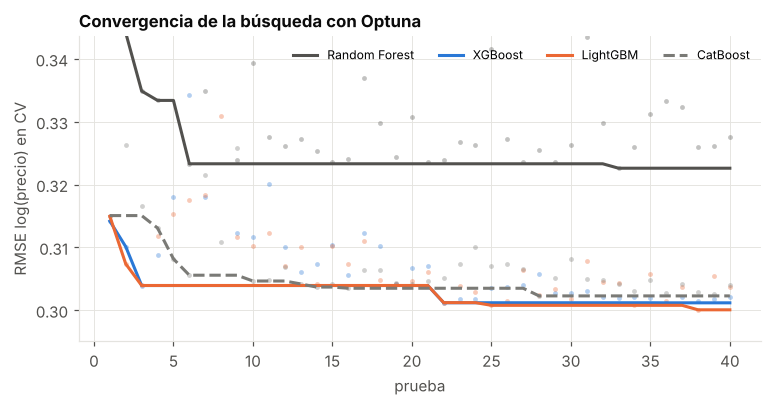

,mejor valor,prueba en que se alcanza,mejor tras 20 pruebas
modelo,,,
CatBoost,0.3023,28.0,0.3035
LightGBM,0.3001,38.0,0.3039
Random Forest,0.3226,33.0,0.3233
XGBoost,0.3012,36.0,0.3039


In [5]:
hist = pd.read_csv(RES / "historial_optuna.csv")
fig, ax = plt.subplots(figsize=(8, 3.6))
for m, color in zip(["random_forest", "xgboost", "lightgbm", "catboost"], [TINTA_2, AZUL, NARANJA, "#7a7a76"]):
    h = hist[hist["modelo"] == m].sort_values("number")
    if h.empty:
        continue
    ax.scatter(h["number"] + 1, h["value"], s=10, color=color, alpha=0.35, linewidth=0)
    ax.plot(h["number"] + 1, h["value"].cummin(), color=color, linewidth=2, label=NOMBRES[m],
            linestyle="--" if m == "catboost" else "-")
ax.set(title="Convergencia de la búsqueda con Optuna", xlabel="prueba", ylabel="RMSE log(precio) en CV")
lim_sup = hist.groupby("modelo")["value"].quantile(0.9).max()
ax.set_ylim(hist["value"].min() - 0.005, lim_sup)
ax.legend(fontsize=8, ncols=4, loc="upper right")
guardar(fig, "08_convergencia_optuna")
mejora = hist.groupby("modelo").apply(lambda h: pd.Series({
    "mejor valor": h["value"].min(),
    "prueba en que se alcanza": int(h.loc[h["value"].idxmin(), "number"]) + 1,
    "mejor tras 20 pruebas": h.sort_values("number")["value"].head(20).min()}), include_groups=False)
mejora.rename(index=NOMBRES).round(4)

**Lectura.**

- **Rangos.** Los rangos se ampliaron tras una primera ejecución en la que varios valores óptimos quedaban en el límite:
  - CatBoost: iteraciones y profundidad;
  - XGBoost y LightGBM: fracción de columnas por árbol;
  - Random Forest: `max_features`.
- **Valores en el borde tras la ampliación.** Los que quedan son límites naturales del parámetro:
  - `min_samples_leaf = 1`;
  - regularización L1/L2 de XGBoost en torno a 0,001, que equivale a no regularizar;
  - `bagging_temperature` cercana a 0.
- **Fracción de columnas en LightGBM.** Su valor óptimo (0,20–0,24) queda cerca del mínimo del rango. Se comprobó que bajar a 0,15 o a 0,10 empeora el error de validación cruzada (0,3025 y 0,3147 frente a 0,3001), así que el óptimo está dentro del rango.
- **Convergencia.** La mayor parte de la mejora se logra en las primeras 20 pruebas. Lo ganado después es de 0,001 a 0,004 en RMSE de log(precio), menos de la mitad de la desviación entre particiones. Con 40 pruebas la búsqueda es suficiente para comparar los modelos, aunque una búsqueda más larga podría afinar algo más los resultados.

## 2. Calidad de las predicciones del mejor modelo

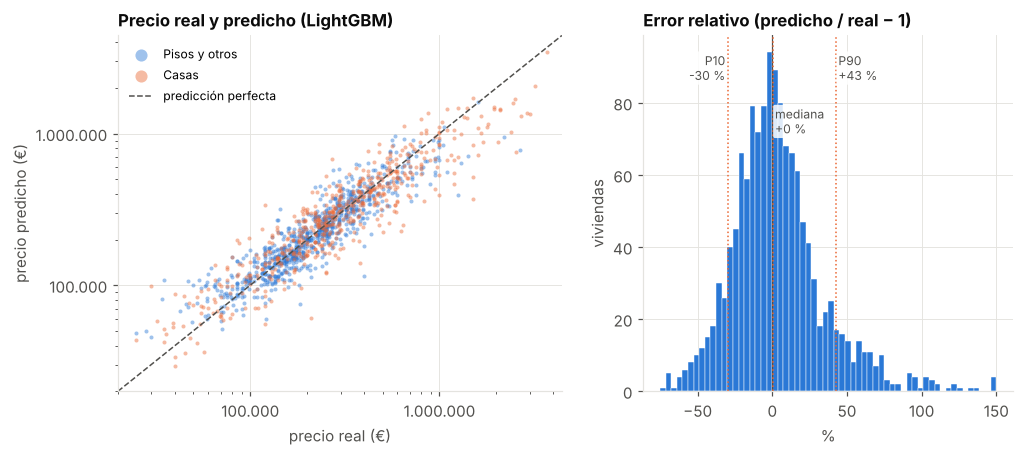

Viviendas con error < 10 %: 31.6% | < 20 %: 57.4% | > 50 %: 10.2%


In [6]:
p = pred.assign(pred=pred[f"pred_{MEJOR}"])
p["error_rel"] = p["pred"] / p["precio_eur"] - 1
p["ape"] = p["error_rel"].abs()
p["grupo"] = np.where(p["tipo_vivienda"] == "casa", "Casas", "Pisos y otros")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw=dict(width_ratios=[1.2, 1]))
for g, color in {"Pisos y otros": AZUL, "Casas": NARANJA}.items():
    s = p[p["grupo"] == g]
    ax[0].scatter(s["precio_eur"], s["pred"], s=7, alpha=0.45, color=color, linewidth=0, label=g)
lim = [p[["precio_eur", "pred"]].min().min() * 0.8, p[["precio_eur", "pred"]].max().max() * 1.2]
ax[0].plot(lim, lim, color=TINTA_2, linewidth=1, linestyle="--", label="predicción perfecta")
ax[0].set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=f"Precio real y predicho ({NOMBRES[MEJOR]})",
          xlabel="precio real (€)", ylabel="precio predicho (€)")
ax[0].xaxis.set_major_formatter(miles); ax[0].yaxis.set_major_formatter(miles)
ax[0].legend(loc="upper left", markerscale=3, fontsize=8)

ax[1].hist(p["error_rel"].clip(-1, 1.5) * 100, bins=60, color=AZUL, edgecolor="white", linewidth=0.3)
ax[1].axvline(0, color=TINTA_2, linewidth=0.8)
ytop = ax[1].get_ylim()[1]
for q, lab, ha, alto in [(0.1, "P10", "right", 0.95), (0.5, "mediana", "left", 0.80), (0.9, "P90", "left", 0.95)]:
    v = p["error_rel"].quantile(q) * 100
    ax[1].axvline(v, color=NARANJA, linewidth=1, linestyle=":")
    ax[1].text(v + (-1.5 if ha == "right" else 1.5), ytop * alto, f"{lab}\n{v:+.0f} %", fontsize=8,
               color=TINTA_2, va="top", ha=ha,
               bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax[1].set(title="Error relativo (predicho / real − 1)", xlabel="%", ylabel="viviendas")
guardar(fig, "02_real_vs_predicho")

print(f"Viviendas con error < 10 %: {(p['ape'] < 0.10).mean():.1%} | < 20 %: {(p['ape'] < 0.20).mean():.1%} | "
      f"> 50 %: {(p['ape'] > 0.50).mean():.1%}")

**Lectura.**

- Las predicciones se reparten en torno a la diagonal, sin sesgo global (error relativo mediano del +0,3 %).
- Un **57 %** de las viviendas se predice con un error inferior al 20 %, y un **32 %** con un error inferior al 10 %. El 80 % central de los errores está entre −30 % y +43 %.
- Hay una cola de sobrestimaciones grandes: un 10 % de las viviendas tiene un error superior al 50 %, y la mitad de ellas pertenece al quintil más barato, como se ve en la sección siguiente.

## 3. Rendimiento por segmentos

Siguiendo la indicación del tutor, se analiza el error del mejor modelo según el tipo de vivienda,
la localización y el tramo de precio, para detectar limitaciones. Se usa el **error porcentual
mediano (MdAPE)**, robusto a casos extremos, y el **sesgo mediano** (si el modelo tiende a sobrestimar,
valores positivos, o a infravalorar, negativos).

In [7]:
def por_segmento(col, orden=None):
    t = p.groupby(col, observed=True).agg(
        viviendas=("ape", "size"), MdAPE_pct=("ape", lambda s: s.median() * 100),
        MAPE_pct=("ape", lambda s: s.mean() * 100),
        sesgo_mediano_pct=("error_rel", lambda s: s.median() * 100),
        dentro_20_pct=("ape", lambda s: (s < 0.2).mean() * 100))
    return (t.reindex(orden) if orden is not None else t.sort_values("MdAPE_pct")).round(1)

p["tramo_precio"] = pd.qcut(p["precio_eur"], 5, labels=[
    f"Q{i + 1}: {a/1000:,.0f}–{b/1000:,.0f} mil €".replace(",", ".")
    for i, (a, b) in enumerate(zip(*[np.quantile(p["precio_eur"], q) for q in
                                    (np.linspace(0, .8, 5), np.linspace(.2, 1, 5))]))])
p["localizacion"] = np.where(p["es_capital"].astype(str).str.lower().isin(["1", "true"]),
                            "Capital", "Resto de municipios")
p["tamano_municipio"] = pd.cut(p.merge(pd.read_csv(RAIZ / "data/procesado/fotocasa_andalucia_limpio.csv",
                                                   usecols=["id_anuncio", "poblacion_2025"], dtype={"id_anuncio": str}),
                                       on="id_anuncio", how="left")["poblacion_2025"],
                               [0, 10_000, 50_000, 200_000, 1e7],
                               labels=["< 10.000 hab.", "10.000–50.000", "50.000–200.000", "> 200.000"])
segmentos = {
    "grupo": por_segmento("grupo"),
    "tipo_vivienda": por_segmento("tipo_vivienda"),
    "provincia": por_segmento("provincia"),
    "localizacion": por_segmento("localizacion"),
    "tamano_municipio": por_segmento("tamano_municipio", ["< 10.000 hab.", "10.000–50.000", "50.000–200.000", "> 200.000"]),
    "tramo_precio": por_segmento("tramo_precio", list(p["tramo_precio"].cat.categories)),
}
pd.concat({k: v for k, v in segmentos.items()}, names=["segmento", "valor"]).to_csv(
    RES / "error_por_segmento.csv", encoding="utf-8-sig")
segmentos["grupo"]

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
grupo,,,,,
Pisos y otros,803,14.5,20.6,0.2,62.4
Casas,559,19.9,26.1,0.3,50.3


In [8]:
segmentos['tipo_vivienda']

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
tipo_vivienda,,,,,
estudio,18,5.5,9.9,4.3,83.3
ático,50,13.0,18.0,3.1,68.0
planta baja,34,13.5,26.3,-2.0,58.8
apartamento,102,13.8,19.7,-1.8,68.6
piso,553,15.2,20.7,-0.5,61.8
dúplex,30,19.0,21.6,-2.5,53.3
casa,559,19.9,26.1,0.3,50.3
sin especificar,16,27.6,28.4,13.6,25.0


In [9]:
segmentos['provincia']

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
provincia,,,,,
Granada,125,13.2,17.7,-1.4,64.8
Almería,129,14.0,21.8,-2.6,60.5
Cádiz,242,14.8,20.7,0.3,61.6
Málaga,329,16.0,23.2,4.7,55.6
Sevilla,117,16.1,23.7,0.6,59.0
Huelva,109,17.6,21.4,-2.0,61.5
Jaén,165,19.4,25.9,-5.1,51.5
Córdoba,146,20.6,27.9,2.0,47.9


In [10]:
pd.concat([segmentos['localizacion'], segmentos['tamano_municipio']])

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
Capital,331,15.8,23.3,-3.5,58.6
Resto de municipios,1031,16.6,22.7,1.6,57.0
< 10.000 hab.,144,16.3,22.1,-3.6,56.2
10.000–50.000,501,17.2,23.4,3.4,56.9
50.000–200.000,455,15.6,21.5,-1.9,60.0
> 200.000,262,17.3,24.5,-0.5,54.6


In [11]:
segmentos['tramo_precio']

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
tramo_precio,,,,,
Q1: 25–133 mil €,275,20.7,32.4,16.3,47.6
Q2: 133–199 mil €,270,14.5,18.6,-0.4,66.7
Q3: 199–280 mil €,279,12.8,18.8,-0.5,67.0
Q4: 280–434 mil €,265,14.2,19.3,-0.1,60.0
Q5: 434–3.695 mil €,273,21.5,24.9,-15.1,45.8


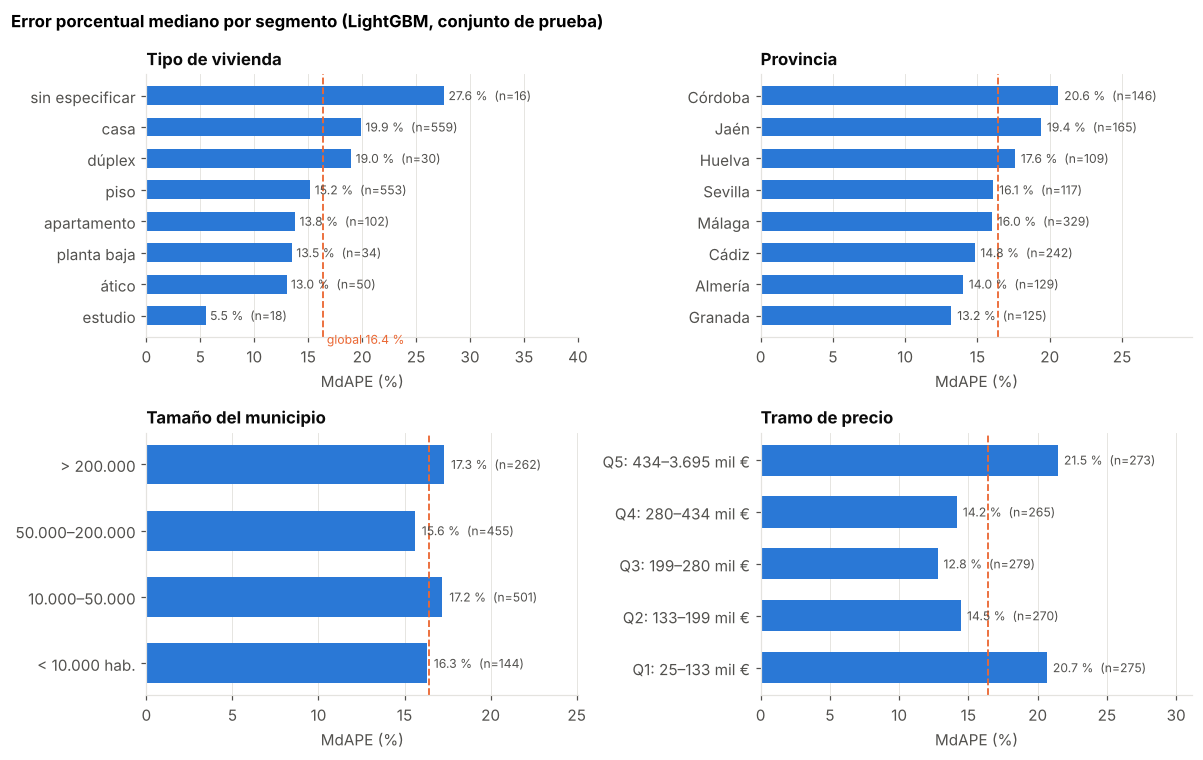

In [12]:
paneles = [("Tipo de vivienda", segmentos["tipo_vivienda"][lambda t: t["viviendas"] >= 15]),
           ("Provincia", segmentos["provincia"]),
           ("Tamaño del municipio", segmentos["tamano_municipio"]),
           ("Tramo de precio", segmentos["tramo_precio"])]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
global_md = p["ape"].median() * 100
for ax, (titulo, t) in zip(axes.ravel(), paneles):
    y = np.arange(len(t))
    ax.barh(y, t["MdAPE_pct"], color=AZUL, height=0.6)
    for yi, (v, n) in enumerate(zip(t["MdAPE_pct"], t["viviendas"])):
        ax.text(v + 0.4, yi, f"{v:.1f} %  (n={n})", va="center", fontsize=8, color=TINTA_2)
    ax.axvline(global_md, color=NARANJA, linewidth=1.2, linestyle="--")
    ax.set_yticks(y, t.index); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(t["MdAPE_pct"].max(), global_md) * 1.45)
    ax.set(title=titulo, xlabel="MdAPE (%)")
axes[0, 0].text(global_md, -0.9, f" global {global_md:.1f} %", color=NARANJA, fontsize=8)
fig.suptitle(f"Error porcentual mediano por segmento ({NOMBRES[MEJOR]}, conjunto de prueba)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "03_error_por_segmento")

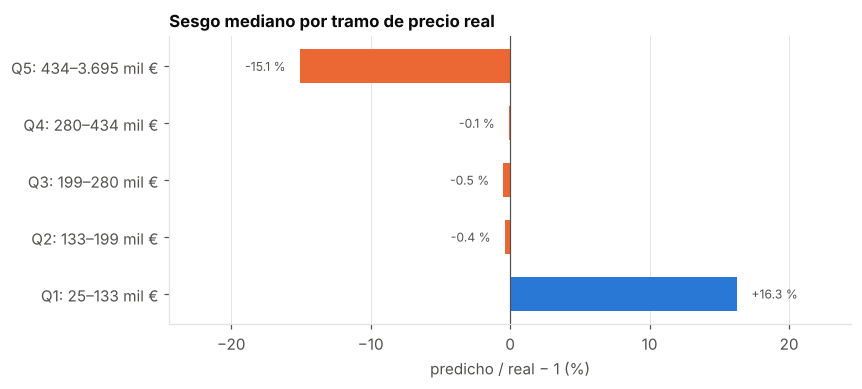

In [13]:
t = segmentos["tramo_precio"]
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(t))
ax.barh(y, t["sesgo_mediano_pct"], color=[NARANJA if v < 0 else AZUL for v in t["sesgo_mediano_pct"]], height=0.6)
for yi, v in enumerate(t["sesgo_mediano_pct"]):
    ax.text(v + (1 if v >= 0 else -1), yi, f"{v:+.1f} %", va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=0.8)
lim = max(abs(t["sesgo_mediano_pct"]).max() * 1.5, 5)
ax.set_xlim(-lim, lim)
ax.set_yticks(y, t.index); ax.grid(axis="y", visible=False)
ax.set(title="Sesgo mediano por tramo de precio real", xlabel="predicho / real − 1 (%)")
guardar(fig, "04_sesgo_por_tramo")

**Lectura.**

- **Tipo de vivienda.** El modelo funciona mejor en pisos y otros (MdAPE 14,5 %) que en casas (19,9 %). La proporción de viviendas con error inferior al 20 % baja del 62 % al 50 %. Las casas son más heterogéneas (parcela, calidades, ubicación aislada) y los datos disponibles las describen peor.
- **Provincia.** El error va del 13,2 % de Granada al 20,6 % de Córdoba y el 19,4 % de Jaén. Las provincias de interior, con mercados más baratos, son las peor predichas, lo que enlaza con el efecto del tramo de precio.
- **Localización.** No hay diferencias relevantes entre capitales (15,8 %) y resto de municipios (16,6 %), ni según el tamaño del municipio (entre el 15,6 % y el 17,3 %). La cobertura territorial lograda permite que el modelo generalice de forma homogénea. En las capitales hay una ligera infravaloración (sesgo mediano −3,5 %).
- **Tramo de precio: la principal limitación.**
  - El error es bajo en los tramos centrales (13–15 %) y sube en los extremos: 20,7 % en el quintil más barato y 21,5 % en el más caro.
  - Hay un sesgo sistemático de **regresión hacia la media**: el modelo sobrestima las viviendas más baratas (+16,3 %) e infravalora las más caras (−15,1 %).
  - Es un comportamiento esperable en cualquier modelo con error cuando se agrupa por el precio real. Además, sugiere que faltan variables que expliquen por qué una vivienda es especialmente barata (estado real, necesidad de venta) o especialmente cara (vistas, calidades, primera línea de playa). Este punto se trabaja en el notebook 03.

## 4. Variables del anuncio (ablación)

El modelo principal no incluye variables que describen el anuncio y no la vivienda (número de fotos,
longitud de la descripción, bajada de precio). Se comprueba su efecto reentrenando el mejor modelo
con los mismos hiperparámetros y las mismas particiones.

In [14]:
ab = pd.read_csv(RES / "ablacion_anuncio.csv").set_index("variante")
tabla_metricas(ab)

,MAE € (CV),± desv.,RMSE € (CV),MdAPE % (CV),R² (CV),MAE € (prueba),RMSE € (prueba),MAPE % (prueba),MdAPE % (prueba),R² (prueba)
variante,,,,,,,,,,
sin variables del anuncio,78091.0,6078.0,163002.0,16.9,0.752,81199.0,180857.0,22.8,16.4,0.738
con variables del anuncio,78444.0,7009.0,163395.0,16.9,0.751,80988.0,182632.0,22.5,15.9,0.733


**Lectura.** Añadir las variables del anuncio (número de fotos, longitud de la descripción, bajada de precio) no mejora el modelo:

- en validación cruzada, el MAE empeora ligeramente (78.444 € frente a 78.091 €);
- en prueba, las diferencias son pequeñas y de signo mixto (MdAPE algo menor, RMSE y R² algo peores).

Se confirma la decisión de excluirlas. El modelo se basa solo en características de la vivienda y de su entorno, sin depender de cómo se redacta o ilustra el anuncio.

## 5. Explicabilidad (SHAP)

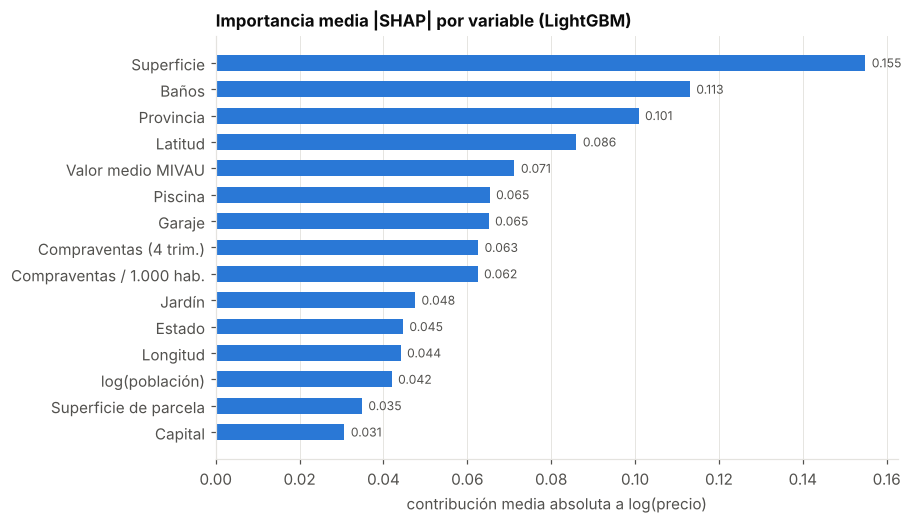

,% del total
superficie_m2,12.2
banos,8.9
provincia,7.9
latitud,6.8
mivau_valor_medio_ref_eur,5.6
piscina,5.1
parking,5.1
mivau_trans_total_4t,4.9
mivau_trans_por_1000hab,4.9
jardin,3.7


In [15]:
X_train, X_test, y_train, y_test, ctx = preparar()
modelo = joblib.load(RAIZ / "models" / f"{MEJOR}.joblib")
explicador = shap.TreeExplainer(modelo)
valores = explicador(X_test)

# Las columnas one-hot de una misma variable se suman para leer la importancia por variable original
def variable_original(c):
    if c == "log_superficie":          # misma variable en otra escala
        return "superficie_m2"
    for pref in ["tipo_vivienda_", "estado_", "orientacion_", "provincia_"]:
        if c.startswith(pref):
            return pref[:-1]
    return c

grupos = pd.Series([variable_original(c) for c in X_test.columns], index=X_test.columns)
shap_df = pd.DataFrame(valores.values, columns=X_test.columns)
importancia = shap_df.abs().T.groupby(grupos).sum().T.mean().sort_values()

NOMBRES_VAR = {
    "superficie_m2": "Superficie", "log_superficie": "Superficie (log)", "banos": "Baños",
    "habitaciones": "Habitaciones", "latitud": "Latitud", "longitud": "Longitud",
    "mivau_valor_medio_ref_eur": "Valor medio MIVAU", "mivau_trans_por_1000hab": "Compraventas / 1.000 hab.",
    "mivau_trans_total_4t": "Compraventas (4 trim.)", "log_poblacion": "log(población)",
    "antiguedad_anos": "Antigüedad", "planta_num": "Planta", "superficie_terreno_m2": "Superficie de parcela",
    "tipo_vivienda": "Tipo de vivienda", "estado": "Estado", "orientacion": "Orientación",
    "provincia": "Provincia", "es_capital": "Capital", "obra_nueva": "Obra nueva", "piscina": "Piscina",
    "ascensor": "Ascensor", "terraza": "Terraza", "parking": "Garaje", "jardin": "Jardín",
    "aire_acondicionado": "Aire acondicionado", "trastero": "Trastero", "calefaccion": "Calefacción",
    "balcon": "Balcón", "cocina_equipada": "Cocina equipada", "patio": "Patio",
    "puerta_blindada": "Puerta blindada", "electrodomesticos": "Electrodomésticos", "domotica": "Domótica",
    "amueblado": "Amueblado", "alquilado": "Alquilado",
}
top = importancia.tail(15)
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(top))
ax.barh(y, top.values, color=AZUL, height=0.6)
for yi, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, yi, f"{v:.3f}", va="center", fontsize=8, color=TINTA_2)
ax.set_yticks(y, [NOMBRES_VAR.get(i, i) for i in top.index]); ax.grid(axis="y", visible=False)
ax.set(title=f"Importancia media |SHAP| por variable ({NOMBRES[MEJOR]})",
       xlabel="contribución media absoluta a log(precio)")
guardar(fig, "05_importancia_shap")
(importancia.sort_values(ascending=False) / importancia.sum() * 100).round(1).head(15).to_frame("% del total")

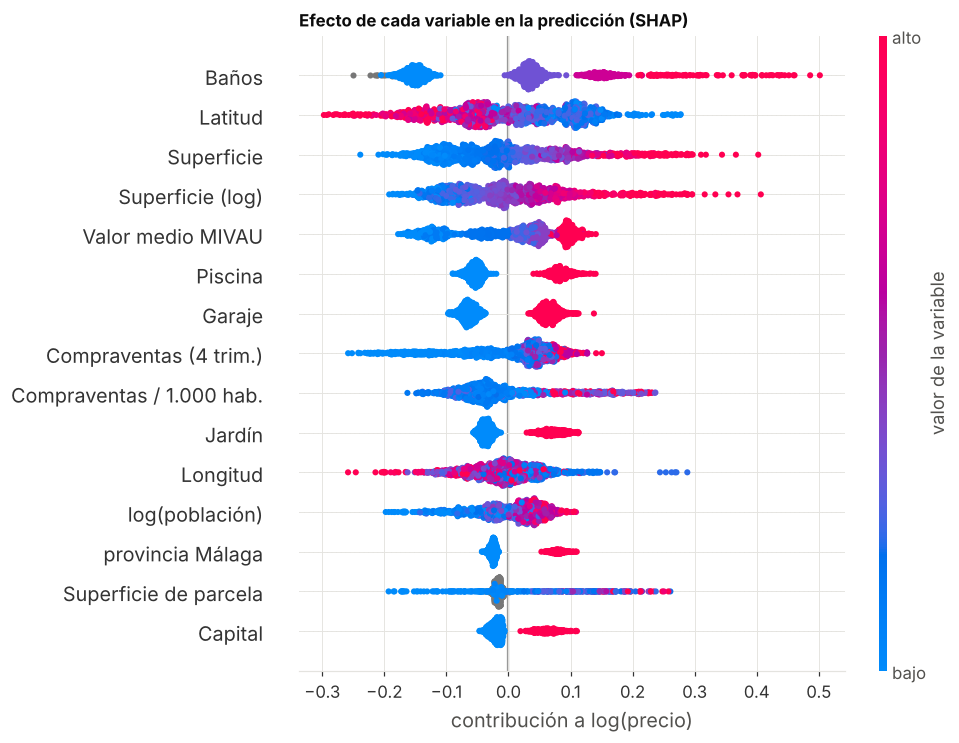

In [16]:
cols_top = [c for c in shap_df.abs().mean().sort_values(ascending=False).index[:15]]
fig = plt.figure(figsize=(8, 6))
shap.plots.beeswarm(valores[:, cols_top], max_display=15, show=False, color_bar_label="valor de la variable")
ax = plt.gca()
ax.set_yticklabels([NOMBRES_VAR.get(t.get_text(), t.get_text().replace("_", " "))
                    for t in ax.get_yticklabels()])
ax.set_title("Efecto de cada variable en la predicción (SHAP)", loc="left", fontweight="bold")
ax.set_xlabel("contribución a log(precio)")
barra = plt.gcf().axes[-1]
barra.set_yticks(barra.get_yticks(), ["bajo", "alto"][:len(barra.get_yticks())])
guardar(plt.gcf(), "06_beeswarm_shap")

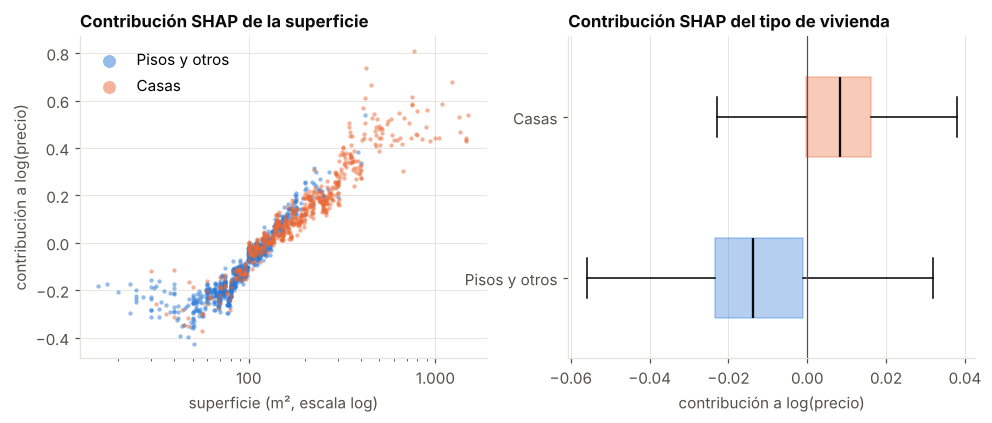

Efecto mediano del tipo: casas +0.008 | pisos -0.014 (en log; diferencia ≈ +2%)


In [17]:
# ¿Recoge el modelo la diferencia entre casas y pisos? Efecto de la superficie según el tipo
sup_cols = [c for c in ["superficie_m2", "log_superficie"] if c in shap_df]
efecto_sup = shap_df[sup_cols].sum(axis=1)
es_casa = (ctx["tipo_vivienda"] == "casa").values
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
for msk, g, color in [(~es_casa, "Pisos y otros", AZUL), (es_casa, "Casas", NARANJA)]:
    ax[0].scatter(X_test.loc[msk, "superficie_m2"], efecto_sup[msk], s=8, alpha=0.5, color=color, linewidth=0, label=g)
ax[0].set(xscale="log", title="Contribución SHAP de la superficie", xlabel="superficie (m², escala log)",
          ylabel="contribución a log(precio)")
ax[0].xaxis.set_major_formatter(miles); ax[0].legend(markerscale=3)

tipo_cols = [c for c in shap_df if c.startswith("tipo_vivienda_")]
efecto_tipo = shap_df[tipo_cols].sum(axis=1)
datos = [efecto_tipo[~es_casa], efecto_tipo[es_casa]]
bp = ax[1].boxplot(datos, orientation="horizontal", tick_labels=["Pisos y otros", "Casas"], showfliers=False,
                   widths=0.5, patch_artist=True, medianprops=dict(color=TINTA, linewidth=1.5))
for patch, color in zip(bp["boxes"], [AZUL, NARANJA]):
    patch.set(facecolor=color, alpha=0.35, edgecolor=color)
ax[1].axvline(0, color=TINTA_2, linewidth=0.8)
ax[1].set(title="Contribución SHAP del tipo de vivienda", xlabel="contribución a log(precio)")
ax[1].grid(axis="y", visible=False)
guardar(fig, "07_superficie_y_tipo_shap")
print(f"Efecto mediano del tipo: casas {np.median(efecto_tipo[es_casa]):+.3f} | pisos {np.median(efecto_tipo[~es_casa]):+.3f} "
      f"(en log; diferencia ≈ {np.exp(np.median(efecto_tipo[es_casa]) - np.median(efecto_tipo[~es_casa])) - 1:+.0%})")

**Lectura.**

- Las variables más influyentes son la **superficie** (12 % de la importancia total) y el número de **baños** (9 %). Les siguen la **ubicación** (provincia, latitud y longitud), el **valor medio de tasación del MIVAU**, la **piscina**, el **garaje** y el volumen de compraventas del municipio. Las variables de enriquecimiento (MIVAU, población) aportan en conjunto una parte importante de la explicación, lo que justifica haberlas incorporado.
- La **latitud** tiene un efecto negativo: cuanto más al norte, es decir, hacia el interior y Sierra Morena, menor precio. Recoge el gradiente entre costa e interior observado en el análisis exploratorio.
- El efecto de la **superficie** es creciente y casi lineal en escala logarítmica, y **muy similar para casas y pisos**.
- La variable **tipo de vivienda** apenas contribuye por sí misma (una diferencia de en torno al 2 % entre casas y pisos). Esto no significa que el modelo ignore la diferencia entre ambos, sino que la recoge a través de variables que los caracterizan mejor: superficie de parcela, jardín, piscina o localización. Es coherente con la indicación del tutor de que un único modelo puede adaptarse a ambos grupos, aunque el error sigue siendo mayor en casas.
- Equipamientos como el garaje, el jardín o el aire acondicionado tienen efectos positivos y moderados, en la dirección esperada.

## 6. Conclusiones, limitaciones y trabajo futuro

**Resultados principales**

1. LightGBM es el modelo de referencia: en validación cruzada tiene un MAE de 78.091 € y un R² de 0,752; en prueba, un MAE de 81.199 €, un R² de 0,738 y una MdAPE del 16,4 %. Está prácticamente empatado con XGBoost y CatBoost, y claramente por delante de Random Forest y de la regresión lineal.
2. Un único modelo para todos los tipos de vivienda es suficiente: la diferencia entre casas y pisos se recoge a través de las variables que los caracterizan.
3. La ubicación y las variables de contexto (MIVAU, INE) están entre las más relevantes, lo que valida el enriquecimiento con fuentes oficiales.
4. Las variables del anuncio no aportan mejora y se excluyen.

**Limitaciones**

- **Regresión hacia la media:** se sobrestiman las viviendas baratas (+16 %) y se infravaloran las caras (−15 %).
- **Peor rendimiento** en casas (MdAPE 19,9 % frente a 14,5 %) y en provincias de interior como Córdoba y Jaén.
- **R² en euros moderado** (0,74), por el peso de las viviendas de precio muy alto.
- **Precio de oferta, no de transacción:** el modelo aprende lo que piden los anunciantes.
- **Una sola fuente y un solo periodo:** un único portal entre septiembre y noviembre de 2026, sin dimensión temporal.
- **Variables incompletas:** la planta, la antigüedad y la orientación tienen muchos valores ausentes.

El notebook 03 aborda parte de estas limitaciones con variables de texto, geografía y renta, y con redes neuronales.